# HomeWise AI — Housing exploration

Exploratory analysis of the Kaggle *House Prices: Advanced Regression Techniques* training data (Ames, Iowa, 2006–2010). All figures are computed from `data/raw/train.csv`. Associations here are not causal.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import load_train, load_test
from src.data_validation import validate_train_test, missing_summary
from src.eda import dataset_overview, target_statistics, numeric_correlations, automatic_insights, detect_outliers
sns.set_theme(style='whitegrid')
train, test = load_train(), load_test()
train.shape, test.shape

((1460, 81), (1459, 80))

## Validation

In [2]:
rep = validate_train_test(train, test)
{k: rep[k] for k in ['schema_match', 'id_overlap', 'ok']}, rep['train']['errors'], rep['train']['warnings']

({'schema_match': True, 'id_overlap': 0, 'ok': True}, [], [])

In [3]:
dataset_overview(train, test)

{'train_records': 1460,
 'test_records': 1459,
 'n_features': 79,
 'n_numerical': 35,
 'n_categorical': 44,
 'missing_cells_train': 7829,
 'columns_with_missing_train': 19,
 'duplicate_records_train': 0}

## Target variable

In [4]:
pd.Series(target_statistics(train['SalePrice'])).round(2)

mean            180921.20
median          163000.00
min              34900.00
max             755000.00
std              79442.50
q1              129975.00
q3              214000.00
iqr              84025.00
skewness             1.88
kurtosis             6.54
log_skewness         0.12
dtype: float64

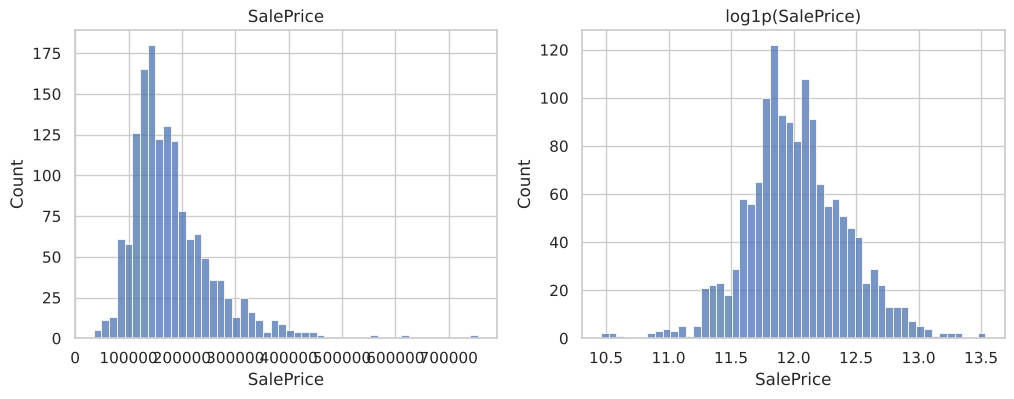

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train['SalePrice'], bins=50, ax=ax[0])
sns.histplot(np.log1p(train['SalePrice']), bins=50, ax=ax[1])
ax[0].set_title('SalePrice'); ax[1].set_title('log1p(SalePrice)');

## Missing values

In [6]:
missing_summary(train.drop(columns=['SalePrice'])).head(20)

,missing,percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


## Correlations with SalePrice

In [7]:
numeric_correlations(train).head(15).round(3)

OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
GarageYrBlt     0.486
MasVnrArea      0.477
Fireplaces      0.467
BsmtFinSF1      0.386
LotFrontage     0.352
Name: SalePrice, dtype: float64

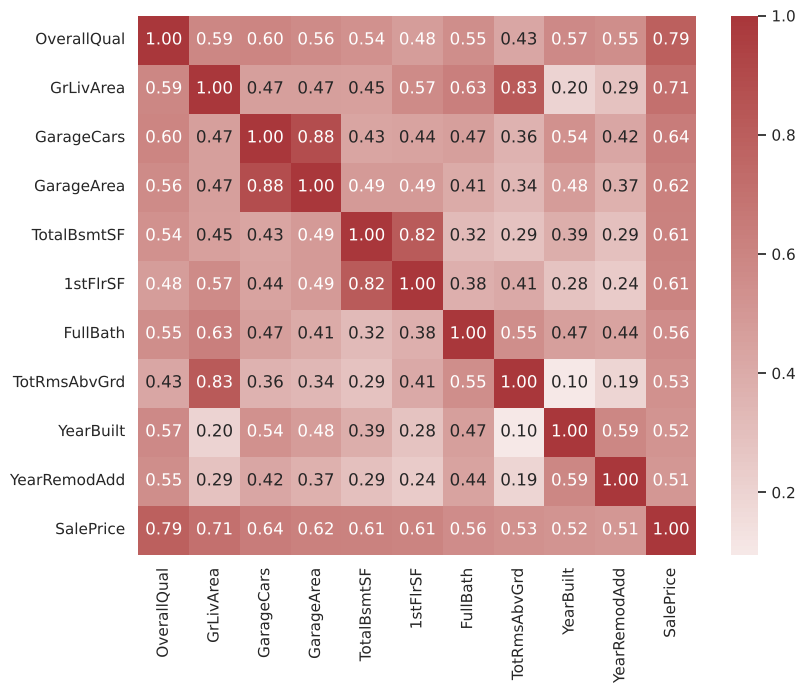

In [8]:
top = numeric_correlations(train).head(10).index.tolist() + ['SalePrice']
plt.figure(figsize=(9, 7))
sns.heatmap(train[top].corr(), annot=True, fmt='.2f', cmap='vlag', center=0);

## Key relationships

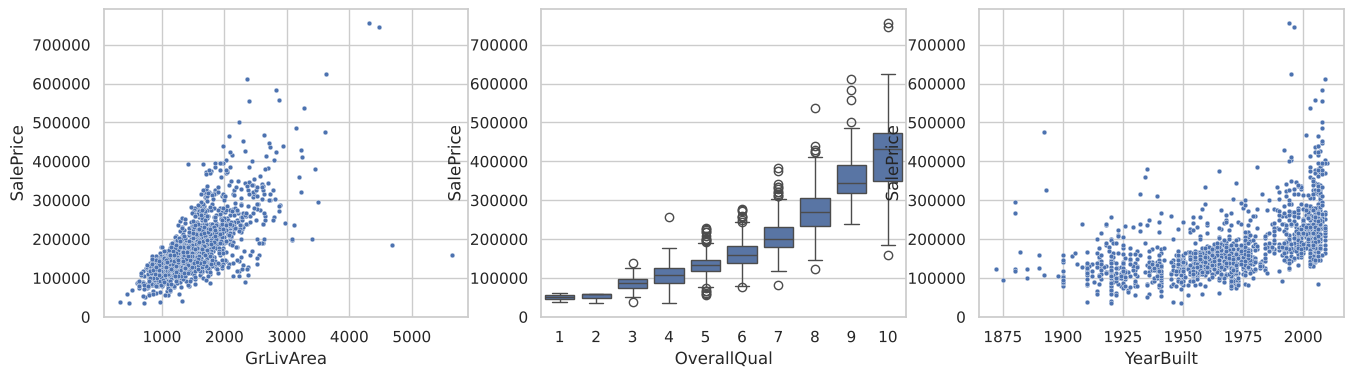

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=train, x='GrLivArea', y='SalePrice', s=12, ax=ax[0])
sns.boxplot(data=train, x='OverallQual', y='SalePrice', ax=ax[1])
sns.scatterplot(data=train, x='YearBuilt', y='SalePrice', s=12, ax=ax[2]);

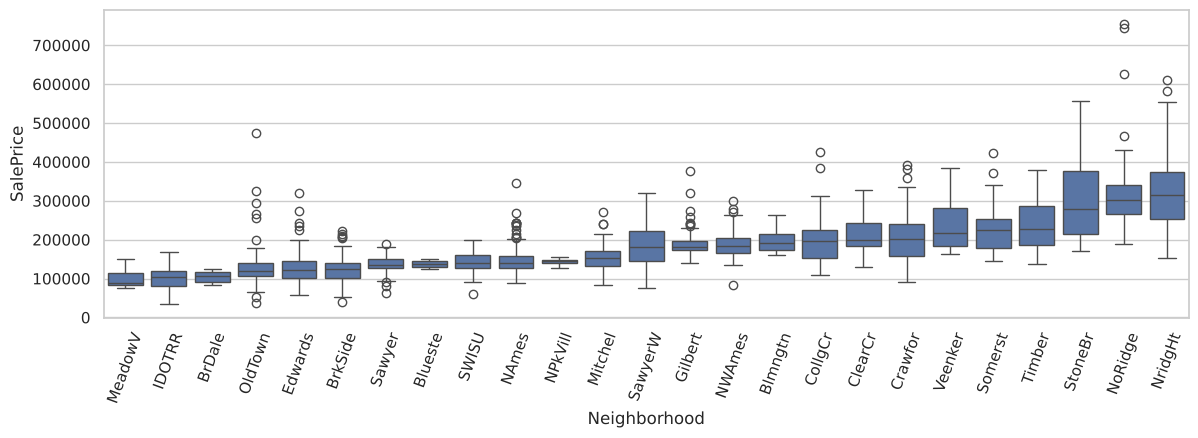

In [10]:
order = train.groupby('Neighborhood')['SalePrice'].median().sort_values().index
plt.figure(figsize=(14, 4))
sns.boxplot(data=train, x='Neighborhood', y='SalePrice', order=order)
plt.xticks(rotation=70);

## Outliers

In [11]:
detect_outliers(train)['large_low_price_rows']

[{'Id': 524,
  'GrLivArea': 4676,
  'SalePrice': 184750,
  'SaleCondition': 'Partial'},
 {'Id': 1299,
  'GrLivArea': 5642,
  'SalePrice': 160000,
  'SaleCondition': 'Partial'}]

## Automatic insights (computed, not hard-coded)

In [12]:
for i in automatic_insights(train):
    print('•', i['question'], '\n ', i['answer'], '\n')

• Does overall quality have a strong relationship with sale price? 
  Yes. Spearman correlation is 0.81. Median price rises from $50,150 at quality 1 to $432,390 at quality 10 (8.6× higher). 

• How does living area relate to historical sale prices? 
  Positively: Pearson r = 0.71. A simple linear fit implies about $10,713 per extra 100 sq ft, before accounting for any other factor. 

• Are newer houses generally more expensive in this dataset? 
  Generally yes (Spearman 0.65). Homes built 2000 or later have a median of $223,750 versus $122,000 for homes built before 1950. Newer homes also tend to be larger and higher quality, so age alone does not explain the gap. 

• How does garage capacity relate to property value? 
  Spearman 0.69. Median price by capacity — 0 cars: $100,000 (n=81), 1 cars: $128,000 (n=369), 2 cars: $177,750 (n=824), 3 cars: $295,000 (n=181), 4 cars: $200,000 (n=5). 

• Which neighborhoods have higher median historical sale prices? 
  Highest medians (≥10 sales): 

## Model results

Trained with `python scripts/train_all.py`; results are read from `outputs/reports`.

In [13]:
pd.read_csv(ROOT / 'outputs/reports/model_comparison.csv')[['Model', 'CV RMSLE', 'Val RMSE', 'Val R2', 'Val MAE']].round(4)

,Model,CV RMSLE,Val RMSE,Val R2,Val MAE
0,Weighted Ensemble,0.1076,19262.3118,0.9421,12482.9562
1,Stacking Ensemble,0.1088,19310.4254,0.9418,12550.5317
2,Lasso Regression,0.1113,20294.1000,0.9358,13309.4990
3,XGBoost,0.1132,21172.4987,0.9301,13571.4264
4,Gradient Boosting,0.1136,19723.4852,0.9393,12833.3993
5,Ridge Regression,0.1136,20272.2339,0.9359,13423.0504
6,LightGBM,0.1145,20922.8159,0.9317,13060.0736
7,Linear Regression,0.1253,23095.0532,0.9168,15410.3427
8,Random Forest,0.1289,23476.9717,0.9140,14409.7036
9,Decision Tree,0.1813,29702.4899,0.8624,19978.0492
